In [22]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout, Conv2D, MaxPooling2D, Input
from tensorflow.keras import utils
from tensorflow.keras.preprocessing import image
import os

(X_train, y_train), (X_test, y_test) = cifar10.load_data()
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

nb_classes = 10
Y_train = utils.to_categorical(y_train, nb_classes)
Y_test = utils.to_categorical(y_test, nb_classes)

classes = ['літак', 'автомобіль', 'птах', 'кіт', 'олень', 'собака', 'жаба', 'кінь', 'корабель', 'вантажівка']
print("Дані CIFAR-10 успішно завантажено та підготовлено!")

Дані CIFAR-10 успішно завантажено та підготовлено!


In [23]:
model = Sequential()
model.add(Input(shape=(32, 32, 3)))

model.add(Conv2D(32, (3, 3), padding='same', activation='relu'))
model.add(Conv2D(32, (3, 3), activation='relu', padding='same'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))

model.add(Conv2D(64, (3, 3), padding='same', activation='relu'))
model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))

model.add(Conv2D(128, (3, 3), padding='same', activation='relu'))
model.add(Conv2D(128, (3, 3), padding='same', activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))

model.add(Flatten())
model.add(Dense(512, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(nb_classes, activation='softmax'))

model.compile(loss='categorical_crossentropy', optimizer='rmsprop', metrics=['accuracy'])
print("Покращену модель скомпільовано!")

Покращену модель скомпільовано!


Epoch 1/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 46s 128ms/step - accuracy: 0.2732 - loss: 1.9706 - val_accuracy: 0.3912 - val_loss: 1.6345
Epoch 2/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 44s 126ms/step - accuracy: 0.4361 - loss: 1.5466 - val_accuracy: 0.5178 - val_loss: 1.3233
Epoch 3/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 50s 141ms/step - accuracy: 0.5259 - loss: 1.3176 - val_accuracy: 0.5784 - val_loss: 1.1880
Epoch 4/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 46s 131ms/step - accuracy: 0.5907 - loss: 1.1585 - val_accuracy: 0.6136 - val_loss: 1.0897
Epoch 5/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 45s 129ms/step - accuracy: 0.6354 - loss: 1.0389 - val_accuracy: 0.6742 - val_loss: 0.9308
Epoch 6/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 46s 131ms/step - accuracy: 0.6698 - loss: 0.9423 - val_accuracy: 0.6798 - val_loss: 0.9346
Epoch 7/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 46s 130ms/step - accuracy: 0.6976 - loss: 0.8649 - val_accuracy: 0.7412 - val_loss: 0.7612
Epoch 8/30
352/352 ━━━━━━━━━━━━━━━━━━━━ 47s 133ms/step - accuracy: 0.7192 - loss: 0

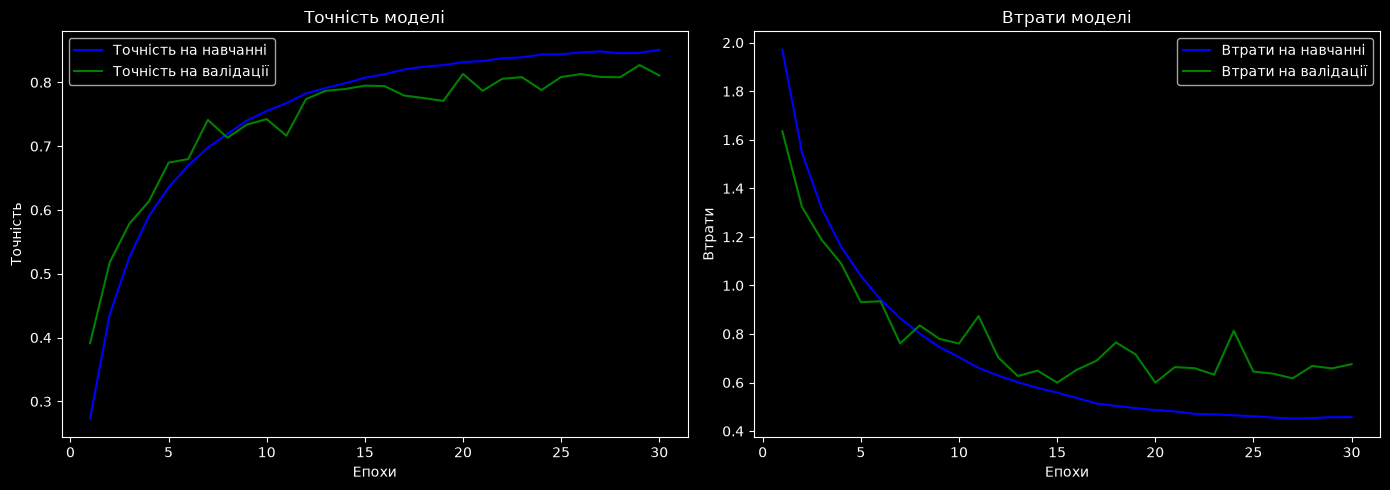

In [24]:
history = model.fit(
    X_train, Y_train,
    batch_size=128,
    epochs=30,
    validation_split=0.1,
    shuffle=True,
    verbose=1
)

scores = model.evaluate(X_test, Y_test, verbose=0)
print(f"\nТочність нової моделі на тестових даних: {scores[1]*100:.2f}%")

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, 'b-', label='Точність на навчанні')
plt.plot(epochs_range, val_acc, 'g-', label='Точність на валідації')
plt.title('Точність моделі')
plt.xlabel('Епохи')
plt.ylabel('Точність')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, 'b-', label='Втрати на навчанні')
plt.plot(epochs_range, val_loss, 'g-', label='Втрати на валідації')
plt.title('Втрати моделі')
plt.xlabel('Епохи')
plt.ylabel('Втрати')
plt.legend()

plt.tight_layout()
plt.show()

In [25]:
model_json = model.to_json()
with open("cifar10_best_model.json", "w") as json_file:
    json_file.write(model_json)
model.save_weights("cifar10_best_model.weights.h5")
print("Архітектуру та ваги моделі успішно збережено на диск!\n")

Архітектуру та ваги моделі успішно збережено на диск!



In [26]:
from tensorflow.keras.models import model_from_json

with open("cifar10_best_model.json", "r") as json_file:
    loaded_model_json = json_file.read()

loaded_model = model_from_json(loaded_model_json)
loaded_model.load_weights("cifar10_best_model.weights.h5")
print("Модель успішно завантажено з диску!")

Модель успішно завантажено з диску!


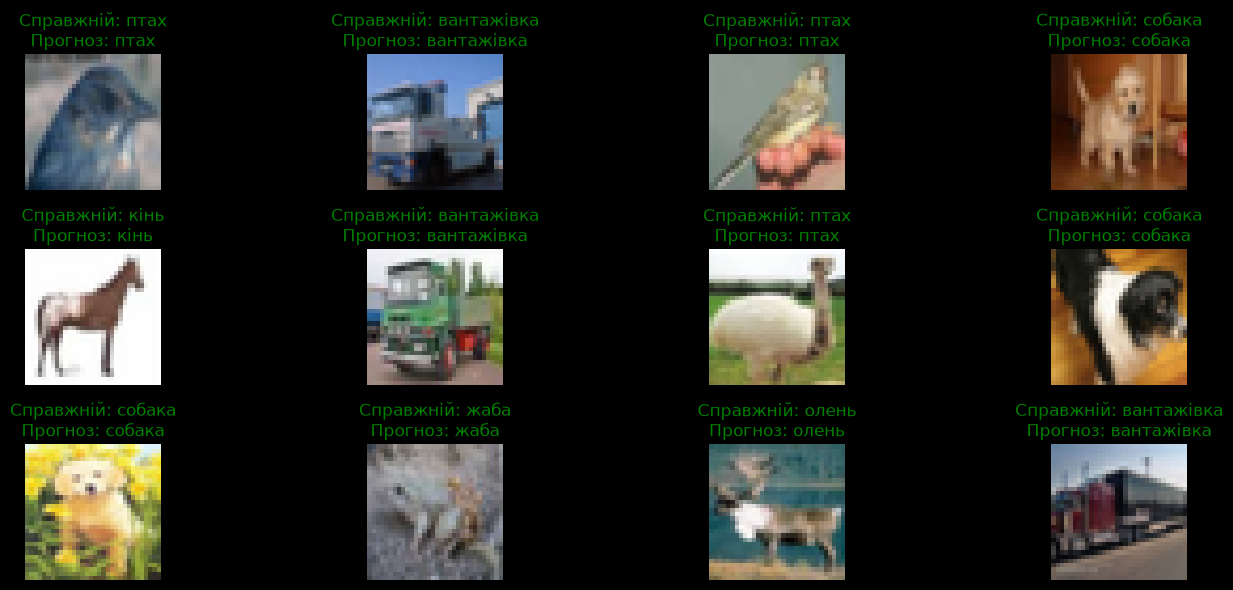

In [35]:
import numpy as np
import matplotlib.pyplot as plt

num_samples = 12
random_indices = np.random.choice(X_test.shape[0], num_samples, replace=False)

plt.figure(figsize=(15, 6))
for i, idx in enumerate(random_indices):
    img = X_test[idx]
    real_label = classes[np.argmax(Y_test[idx])]

    x = np.expand_dims(img, axis=0)
    prediction = loaded_model.predict(x, verbose=0)
    predicted_label = classes[np.argmax(prediction)]
    
    plt.subplot(3, 4, i + 1)
    plt.imshow(img)

    color = 'green' if real_label == predicted_label else 'red'
    plt.title(f"Справжній: {real_label}\nПрогноз: {predicted_label}", color=color)
    plt.axis('off')

plt.tight_layout()
plt.show()

--- Починаємо розпізнавання власних зображень ---


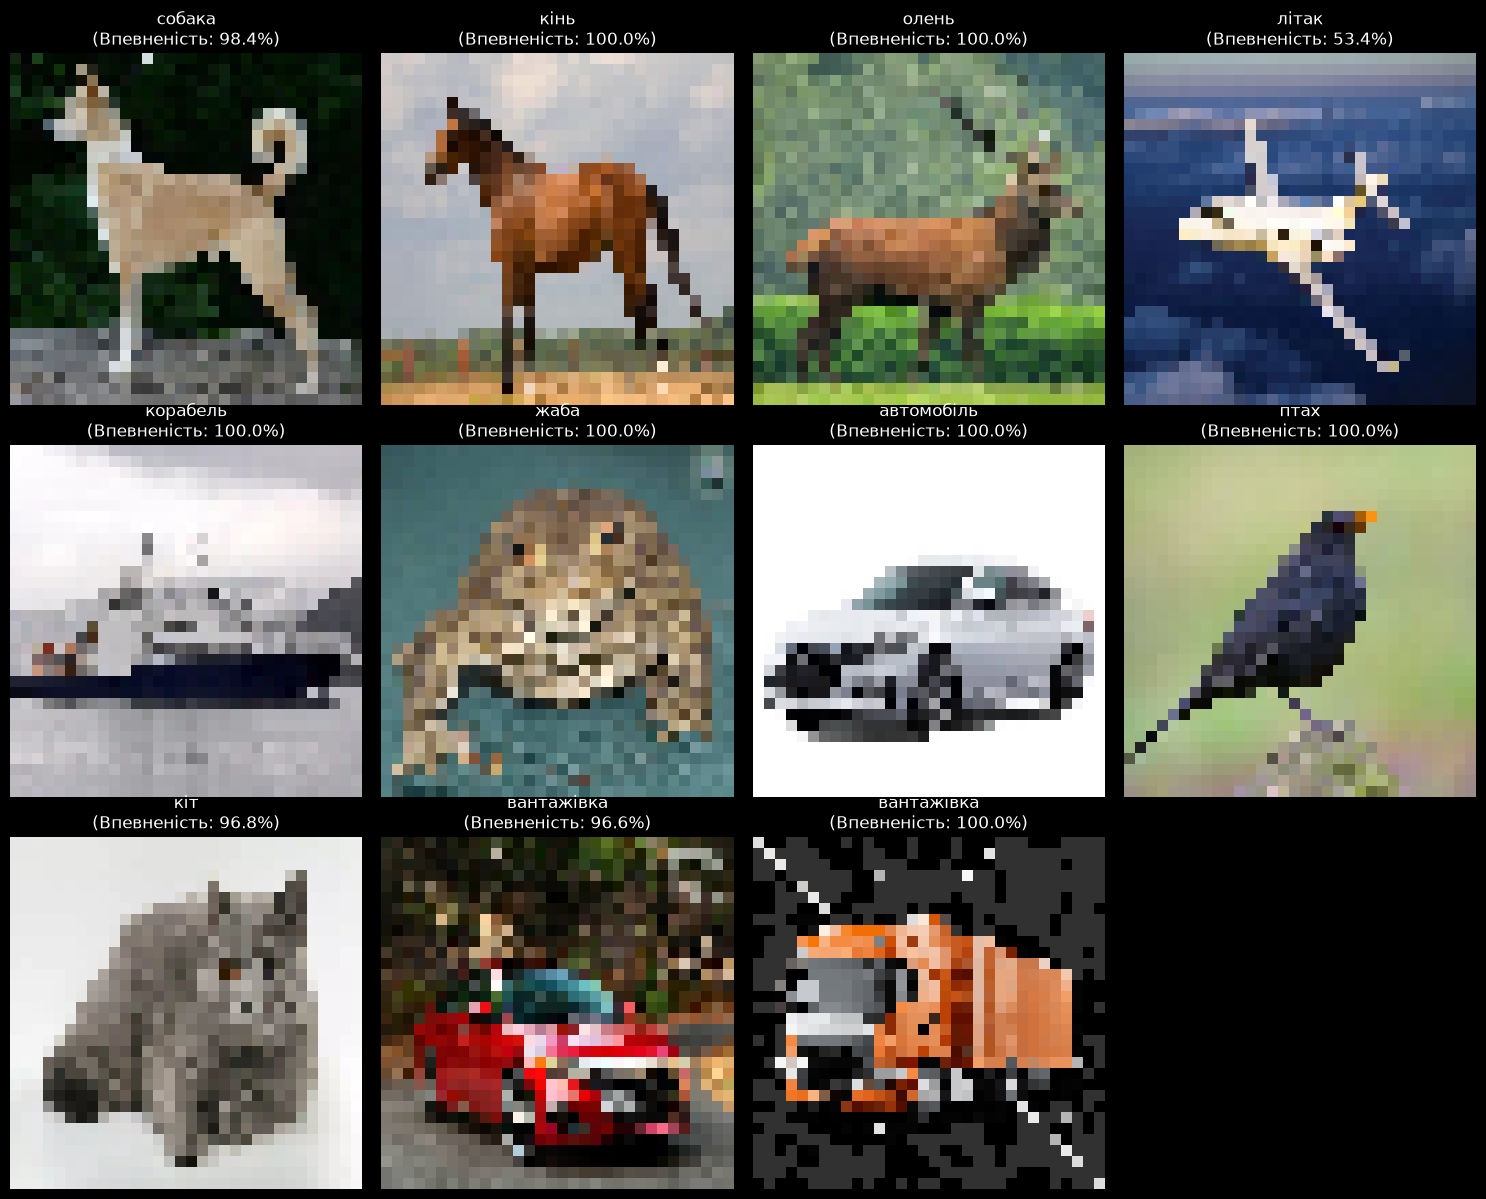

In [30]:
import os
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt

image_folder = 'my_images'

if os.path.exists(image_folder) and len(os.listdir(image_folder)) > 0:
    print("--- Починаємо розпізнавання власних зображень ---")
    files = [f for f in os.listdir(image_folder) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.webp'))]
    plt.figure(figsize=(15, 4 * ((len(files) + 3) // 4)))

    for i, file_name in enumerate(files):
        img_path = os.path.join(image_folder, file_name)
        img = image.load_img(img_path, target_size=(32, 32))
        x = image.img_to_array(img)
        x /= 255.0
        x = np.expand_dims(x, axis=0)

        prediction = loaded_model.predict(x, verbose=0)
        predicted_class = np.argmax(prediction)
        confidence = np.max(prediction) * 100

        plt.subplot(((len(files) + 3) // 4), 4, i + 1)
        plt.imshow(img)
        plt.title(f"{classes[predicted_class]}\n(Впевненість: {confidence:.1f}%)")
        plt.axis('off')

    plt.tight_layout()
    plt.show()
else:
    print(f"Папка {image_folder} порожня або не існує! Завантажте 10-20 зображень.")